In [1]:
import numpy as np
import pandas as pd
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from quantificationlib.baselines.cc import CC
import sys
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append('../')
from src.quantifiers.level import LocalLevelQuantifiers
from src.data.bag_generator import generate_hierarchical_bags
from src.metrics.evaluator import HierarchicalPrevalenceEvaluator

In [2]:
classes_folhas_alvo = ["Root.A.B.C", "Root.A.B.D", "Root.A.E", "Root.F.G", "Root.F.H"]

X_bruto, y_inteiros = make_blobs(
  n_samples=2000, 
  n_features=10, 
  centers=len(classes_folhas_alvo), 
  cluster_std=4.0, # Um pouco de ruído para não ficar fácil demais
  random_state=42
)

y_hierarquico = np.array([classes_folhas_alvo[i] for i in y_inteiros])

X_treino, X_teste, y_treino, y_teste = train_test_split(
  X_bruto, y_hierarquico, test_size=0.5, random_state=42
)

print(f"Total de Treino: {len(X_treino)} amostras")
print(f"Total de Teste (Pool para Bags): {len(X_teste)} amostras")
print(f"Exemplo de y_treino: {y_treino[:5]}")

Total de Treino: 1000 amostras
Total de Teste (Pool para Bags): 1000 amostras
Exemplo de y_treino: ['Root.F.G' 'Root.F.G' 'Root.F.H' 'Root.F.H' 'Root.A.E']


In [3]:
print("1. Treinando o modelo Local Classifier per Level (LCL)...")
quantificador_base = CC(RandomForestClassifier(n_estimators=50, random_state=42))
lcl_model = LocalLevelQuantifiers(base_quantifier=quantificador_base, sep=".")
lcl_model.fit(X_treino, y_treino)

print("\n2. Gerando Bags de Teste (Uniformes e Extremas)...")
bags_teste = generate_hierarchical_bags(
  X_teste, y_teste, 
  bag_size=150, 
  n_bags_uniform=5, 
  n_bags_extreme=5
)

print("\n3. Iniciando Avaliação Hierárquica (hMAE)...\n")
avaliador = HierarchicalPrevalenceEvaluator(sep=".")
resultados = []

for i, bag in enumerate(bags_teste):
  # Tipagem do Shift
  tipo_shift = "Uniforme" if bag['alpha_shift'] == 1.0 else "Extremo"
  
  # Previsão (LCL já aplica o Top-Down internamente)
  prev_estimada = lcl_model.quantify(bag['X'])
  
  # Avaliação (Compara o Dicionário de Previsões com o 'y' real da Bag)
  erros_nivel, hmae = avaliador.evaluate_from_prevalences(bag['y'], prev_estimada)
  
  resultados.append({
    "Bag": f"Bag {i+1}",
    "Shift": tipo_shift,
    "Tamanho Real": bag['actual_size'],
    "hAE": round(hmae, 4)
  })

1. Treinando o modelo Local Classifier per Level (LCL)...

2. Gerando Bags de Teste (Uniformes e Extremas)...

3. Iniciando Avaliação Hierárquica (hMAE)...



In [4]:
df_resultados = pd.DataFrame(resultados)
display(df_resultados)

,Bag,Shift,Tamanho Real,hAE
0,Bag 1,Uniforme,150,0.0207
1,Bag 2,Uniforme,150,0.0389
2,Bag 3,Uniforme,150,0.0603
3,Bag 4,Uniforme,150,0.0688
4,Bag 5,Uniforme,150,0.0213
5,Bag 6,Extremo,150,0.0495
6,Bag 7,Extremo,150,0.0804
7,Bag 8,Extremo,150,0.0153
8,Bag 9,Extremo,150,0.0067
9,Bag 10,Extremo,150,0.0067


In [5]:
print("\nMédia do hAE por Shift:")
display(df_resultados.groupby("Shift")["hAE"].mean().reset_index())


Média do hAE por Shift:


,Shift,hAE
0,Extremo,0.03172
1,Uniforme,0.04200


In [6]:
# Lista para guardar os dados detalhados para o gráfico
dados_plot_niveis = []

print("Avaliando as bags e coletando os erros por nível...")

for i, bag in enumerate(bags_teste):
  tipo_shift = "Uniforme" if bag['alpha_shift'] == 1.0 else "Extremo"
  
  # Faz a previsão e a avaliação
  prev_estimada = lcl_model.quantify(bag['X'])
  erros_nivel, hmae = avaliador.evaluate_from_prevalences(bag['y'], prev_estimada)
  
  # Guarda o erro de CADA nível separadamente
  for nivel, erro_absoluto in erros_nivel.items():
    dados_plot_niveis.append({
      "Bag": f"Bag {i+1}",
      "Shift": tipo_shift,
      "Nível": nivel,
      "MAE": erro_absoluto
    })

# Converte para um DataFrame do Pandas
df_erros_niveis = pd.DataFrame(dados_plot_niveis)

print("Coleta concluída! Prontos para plotar.")

Avaliando as bags e coletando os erros por nível...
Coleta concluída! Prontos para plotar.


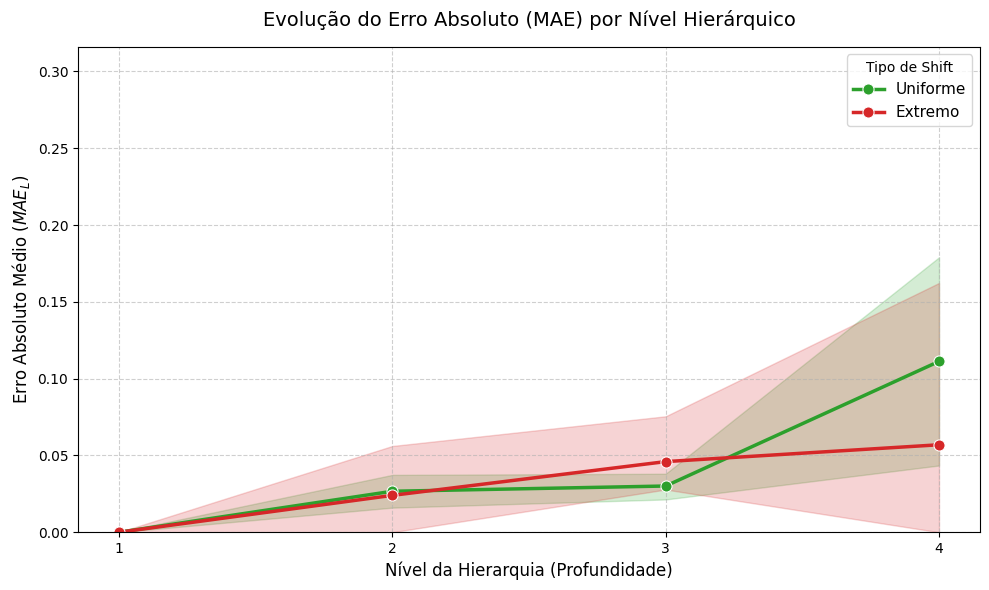

In [7]:
def plotar_erro_por_nivel(df_erros):
  """
  Gera um gráfico de linhas mostrando a evolução do erro médio 
  conforme a profundidade do nível hierárquico.
  """
  plt.figure(figsize=(10, 6))
  
  # O seaborn.lineplot automaticamente tira a média das bags e plota uma sombra 
  # de intervalo de confiança (que mostra a variação entre as bags)
  ax = sns.lineplot(
    data=df_erros, 
    x='Nível', 
    y='MAE', 
    hue='Shift', 
    marker='o',      # Coloca uma bolinha em cada nível
    markersize=8,
    linewidth=2.5,
    palette=['#2ca02c', '#d62728'] # Verde para Uniforme, Vermelho para Extremo
  )
  
  # Estilização do gráfico
  plt.title('Evolução do Erro Absoluto (MAE) por Nível Hierárquico', fontsize=14, pad=15)
  plt.xlabel('Nível da Hierarquia (Profundidade)', fontsize=12)
  plt.ylabel('Erro Absoluto Médio ($MAE_L$)', fontsize=12)
  
  # Garante que o eixo X mostre apenas números inteiros (Nível 1, 2, 3...)
  niveis_unicos = df_erros['Nível'].unique()
  plt.xticks(niveis_unicos)
  
  # Ajusta o eixo Y para começar do zero
  plt.ylim(0, df_erros['MAE'].max() * 1.2)
  
  plt.grid(True, linestyle='--', alpha=0.6)
  plt.legend(title='Tipo de Shift', fontsize=11)
  
  plt.tight_layout()
  plt.show()

# Chamando a função com o nosso DataFrame
plotar_erro_por_nivel(df_erros_niveis)